--- TABELA: CHUVA x CASOS (2024) ---
   Data  Chuva_Acumulada_mm  Total_Casos
2024-01             2724.63          105
2024-02             4233.57          359
2024-03             2469.25          524
2024-04             2970.36          489
2024-05             6263.53          178
2024-06             8209.87          188
2024-07             3640.24          137
2024-08             2480.05          136
2024-09             1173.71           85
2024-10              673.84          115
2024-11              164.61           91
2024-12              377.72           74
  TOTAL            35381.38         2481


--- TABELA: CHUVA x CASOS (2025) ---
   Data  Chuva_Acumulada_mm  Total_Casos
2025-01             2515.43          113
2025-02             2643.70          124
2025-03             1596.07          123
2025-04              687.57          182
2025-05             3882.29          129
2025-06             3174.85          158
2025-07             2161.05          166
2025-08             17

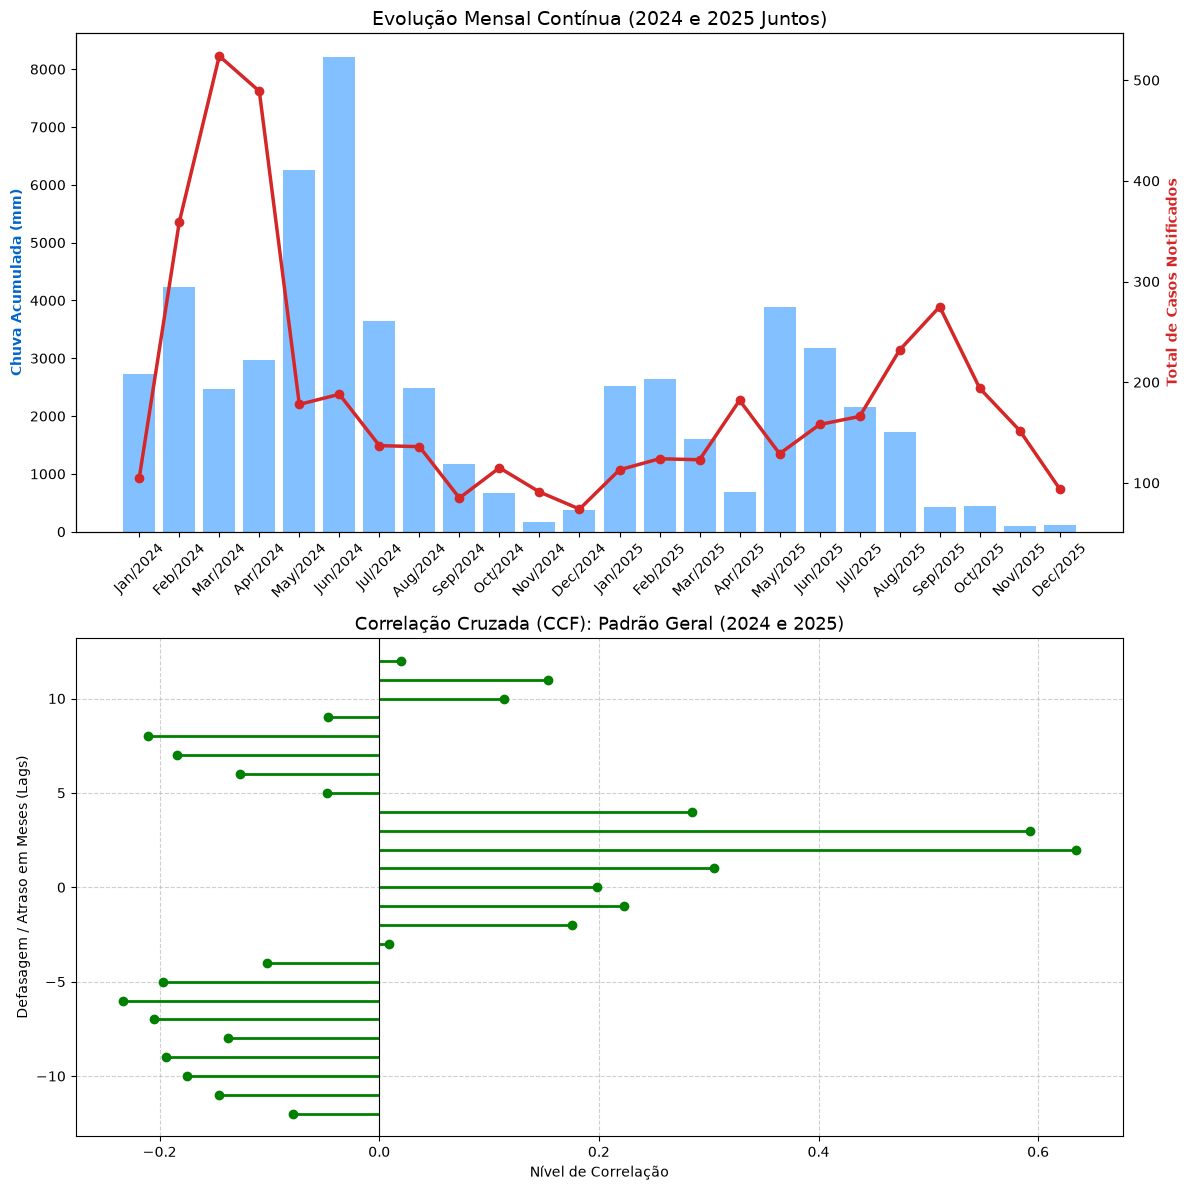

In [3]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import matplotlib.pyplot as plt

# 1. Carregar os dados de Chuva (2024 e 2025)
df_chuva_2024 = pd.read_excel('historico_pluvio_mensal_01_01_2024_a_31_12_2025.xlsx')
df_chuva_2025 = pd.read_excel('historico_pluvio_mensal_01_01_2025_a_31_12_2025.xlsx')
df_chuva = pd.concat([df_chuva_2024, df_chuva_2025], ignore_index=True)

# 2. Carregar os dados de Casos (Apenas a coluna DT_NOTIFIC para otimizar memória)
df_casos_2024 = pd.read_csv('resources_b0490f6f-f51a-4471-bc9e-a82c59b8e59e_chikon-2024.csv', sep=';', low_memory=False, usecols=['DT_NOTIFIC'])
df_casos_2025 = pd.read_csv('resources_b300a634-1ab7-49fc-8592-4b45227822a8_casos-confirmados-de-chikungunya-em-2025.csv', sep=';', low_memory=False, usecols=['DT_NOTIFIC'])

# 3. Tratar as datas dos casos 
df_casos_2024['Data_Notificacao'] = pd.to_datetime(df_casos_2024['DT_NOTIFIC'], errors='coerce')
df_casos_2025['Data_Notificacao'] = pd.to_datetime(df_casos_2025['DT_NOTIFIC'], errors='coerce', dayfirst=True)
df_casos = pd.concat([df_casos_2024, df_casos_2025], ignore_index=True)
casos_mensais = df_casos.set_index('Data_Notificacao').resample('MS').size().rename('Total_Casos')

# 4. Preparar a base de Chuva (Recife)
df_chuva_recife = df_chuva[df_chuva['Município'] == 'Recife'].copy()
meses = {'Janeiro': 1, 'Fevereiro': 2, 'Março': 3, 'Abril': 4, 'Maio': 5, 'Junho': 6,
         'Julho': 7, 'Agosto': 8, 'Setembro': 9, 'Outubro': 10, 'Novembro': 11, 'Dezembro': 12}
chuva_long = df_chuva_recife.melt(id_vars=['Ano'], value_vars=meses.keys(), var_name='Mes_Nome', value_name='Precipitacao')
chuva_long['Precipitacao'] = pd.to_numeric(chuva_long['Precipitacao'].astype(str).str.replace(',', '.'), errors='coerce')
chuva_long['Mes'] = chuva_long['Mes_Nome'].map(meses)
chuva_long['Data'] = pd.to_datetime(chuva_long['Ano'].astype(str) + '-' + chuva_long['Mes'].astype(str) + '-01')
chuva_mensal = chuva_long.groupby('Data')['Precipitacao'].sum().rename('Chuva_Acumulada_mm')

# 5. SEPARAR AS TABELAS POR ANO NO TERMINAL
df_grafico = pd.concat([chuva_mensal, casos_mensais], axis=1).dropna()
df_grafico['Ano'] = df_grafico.index.year

def imprimir_tabela_ano(df_ano, ano_titulo):
    df_tab = df_ano[['Chuva_Acumulada_mm', 'Total_Casos']].reset_index().rename(columns={'index': 'Data'})
    df_tab['Data'] = df_tab['Data'].dt.strftime('%Y-%m')
    
    total_chuva = df_tab['Chuva_Acumulada_mm'].sum()
    total_casos = df_tab['Total_Casos'].sum()
    linha_total = pd.DataFrame([{'Data': 'TOTAL', 'Chuva_Acumulada_mm': total_chuva, 'Total_Casos': total_casos}])
    df_tab = pd.concat([df_tab, linha_total], ignore_index=True)
    
    print(f"--- TABELA: CHUVA x CASOS ({ano_titulo}) ---")
    print(df_tab.to_string(index=False))
    print("\n" + "="*50 + "\n")

# Imprime as tabelas no terminal
imprimir_tabela_ano(df_grafico[df_grafico['Ano'] == 2024], "2024")
imprimir_tabela_ano(df_grafico[df_grafico['Ano'] == 2025], "2025")

# 6. PLOTAR OS GRÁFICOS (Sazonalidade 24 meses + CCF Horizontal)
fig, (ax1, ax3) = plt.subplots(2, 1, figsize=(12, 12))

# --- Gráfico 1: Sazonalidade 2024 e 2025 Juntos (24 meses contínuos) ---
meses_str = df_grafico.index.strftime('%b/%Y')
ax1.bar(meses_str, df_grafico['Chuva_Acumulada_mm'], color='#4da6ff', alpha=0.7, label='Chuva (mm)')
ax1.set_ylabel('Chuva Acumulada (mm)', color='#0066cc', fontweight='bold')
ax1.tick_params(axis='x', rotation=45)

ax1_twin = ax1.twinx()
ax1_twin.plot(meses_str, df_grafico['Total_Casos'], color='#d62728', marker='o', linewidth=2.5, label='Casos')
ax1_twin.set_ylabel('Total de Casos Notificados', color='#d62728', fontweight='bold')
ax1.set_title('Evolução Mensal Contínua (2024 e 2025 Juntos)', fontsize=14)

# --- Gráfico 2: CCF (Ambos os anos juntos - Versão Horizontal) ---
chuva_calc = df_grafico['Chuva_Acumulada_mm'] - df_grafico['Chuva_Acumulada_mm'].mean()
casos_calc = df_grafico['Total_Casos'] - df_grafico['Total_Casos'].mean()

# Calcula a matemática com 12 meses de limite
lags, c, _, _ = ax3.xcorr(chuva_calc, casos_calc, maxlags=12)
ax3.clear() # Limpa a versão vertical padrão

# Redesenha manualmente as linhas na horizontal
ax3.hlines(lags, 0, c, colors='green', linewidth=2)
ax3.plot(c, lags, 'go')

# Rótulos invertidos (Defasagem no Y, Correlação no X)
ax3.set_title('Correlação Cruzada (CCF): Padrão Geral (2024 e 2025)', fontsize=13)
ax3.set_ylabel('Defasagem / Atraso em Meses (Lags)')
ax3.set_xlabel('Nível de Correlação')
ax3.grid(True, linestyle='--', alpha=0.6)
ax3.axvline(0, color='black', linewidth=0.8)

plt.tight_layout()
plt.show()